# 01. Подготовка данных: Amazon Movies & TV
Файл `common.py` должен лежать в `WORK_DIR`. Данные и результаты всех следующих ноутбуков складываются туда же.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import gzip
import importlib
import json
import os
import platform
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    default_work_dir = '/content/drive/MyDrive/code2repo/kan_rec'
except ImportError:
    default_work_dir = os.path.abspath('./kan_rec')

WORK_DIR = os.environ.get('KAN_REC_DIR', default_work_dir)
DATASET = 'amazon'

os.makedirs(WORK_DIR, exist_ok=True)
sys.path.insert(0, WORK_DIR)

import common
importlib.reload(common)

paths = common.dataset_paths(WORK_DIR, DATASET)
os.makedirs(paths['results'], exist_ok=True)
device = common.check_gpu()

Tesla T4, 14.6 GiB, sm_75, torch 2.11.0+cu130


In [3]:
import importlib.metadata as metadata

packages = ['torch', 'numpy', 'pandas', 'scipy', 'pykan', 'scikit-learn', 'matplotlib']
env_lines = [f'python {platform.python_version()}']
for name in packages:
    try:
        env_lines.append(f'{name}=={metadata.version(name)}')
    except metadata.PackageNotFoundError:
        env_lines.append(f'{name}: не установлен')
env_lines.append(f'GPU: {common.gpu_name()}')

with open(f"{paths['results']}/env.txt", 'w') as f:
    f.write('\n'.join(env_lines) + '\n')
print('\n'.join(env_lines))

python 3.13.16
torch==2.11.0+cu130
numpy==2.1.3
pandas==2.2.3
scipy==1.16.3
pykan: не установлен
scikit-learn==1.6.1
matplotlib==3.10.0
GPU: Tesla T4


## Загрузка отзывов
Если gdown упирается в квоту Google, сделайте копию файла на свой диск и укажите путь в `REVIEWS_PATH`.

In [4]:
import gdown

REVIEWS_PATH = os.path.join(WORK_DIR, 'Movies_5.json.gz')
REVIEWS_FILE_ID = '1m_Lo5_aLV4FsgDMlYxE_ajW9bfv416dj'

if not os.path.exists(REVIEWS_PATH):
    gdown.download(id=REVIEWS_FILE_ID, output=REVIEWS_PATH)
print(f'{os.path.getsize(REVIEWS_PATH) / 1e6:.0f} MB')

Downloading...
From (original): https://drive.google.com/uc?id=1m_Lo5_aLV4FsgDMlYxE_ajW9bfv416dj
From (redirected): https://drive.google.com/uc?id=1m_Lo5_aLV4FsgDMlYxE_ajW9bfv416dj&confirm=t&uuid=91edbd08-4878-4d44-8b65-a5ed7db71b0c
To: /content/drive/MyDrive/code2repo/kan_rec/Movies_5.json.gz
100%|██████████| 791M/791M [00:12<00:00, 65.6MB/s]

791 MB


In [5]:
MAX_LINES = None  # для отладки, например 500_000

users, items, ratings, timestamps = [], [], [], []
started = time.time()

with gzip.open(REVIEWS_PATH, 'rt', encoding='utf-8') as f:
    for line_no, line in enumerate(f):
        if MAX_LINES and line_no >= MAX_LINES:
            break
        review = json.loads(line)
        if line_no == 0:
            print('поля:', list(review.keys()))
        users.append(review.get('user_id') or review.get('reviewerID'))
        items.append(review.get('parent_asin') or review.get('asin'))
        ratings.append(review.get('rating', review.get('overall')))
        timestamps.append(review.get('timestamp', review.get('unixReviewTime')))

df = pd.DataFrame({'user': users, 'item': items, 'rating': ratings, 'ts': timestamps})
del users, items, ratings, timestamps

print(f'{len(df):,} строк за {time.time() - started:.0f} с')
print('пропуски:', df.isna().sum().to_dict())
df.to_parquet(f'{WORK_DIR}/raw_interactions.parquet')

поля: ['overall', 'verified', 'reviewTime', 'reviewerID', 'asin', 'style', 'reviewerName', 'reviewText', 'summary', 'unixReviewTime']
3,410,019 строк за 44 с
пропуски: {'user': 0, 'item': 0, 'rating': 0, 'ts': 0}


## EDA

users=297,529  items=60,175  interactions=3,410,019
density=0.019046%  avg len=11.46
дубликаты (user, item): 127640
рейтинги: {1.0: 0.057, 2.0: 0.051, 3.0: 0.103, 4.0: 0.195, 5.0: 0.595}
длина истории: {0.5: 7.0, 0.75: 11.0, 0.9: 19.0, 0.95: 29.0, 0.99: 71.0} max 3509
популярность айтема: {0.5: 16.0, 0.75: 40.0, 0.9: 108.0, 0.95: 215.0, 0.99: 749.0} max 7195


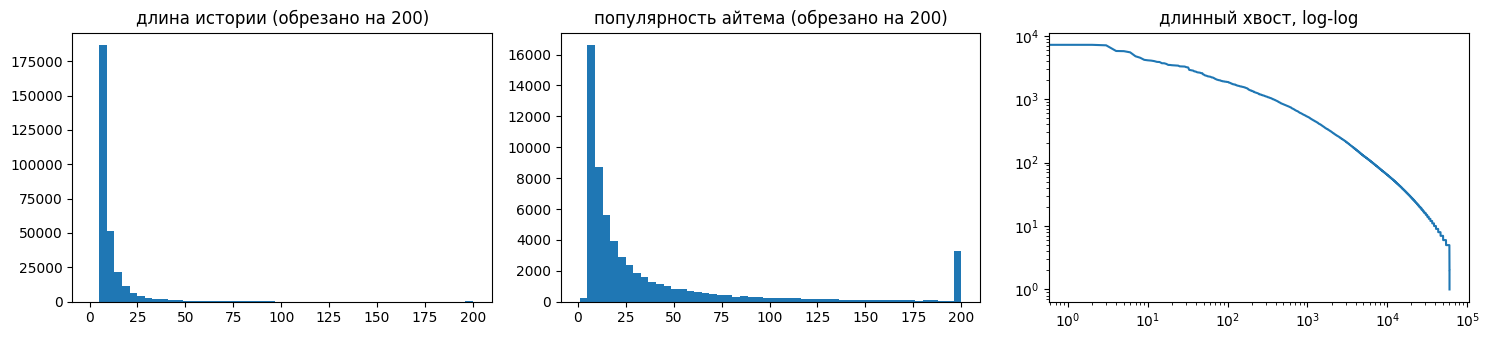

In [6]:
n_users, n_items, n_rows = df.user.nunique(), df.item.nunique(), len(df)
user_len = df.groupby('user').size()
item_pop = df.groupby('item').size()
quantiles = [.5, .75, .9, .95, .99]

print(f'users={n_users:,}  items={n_items:,}  interactions={n_rows:,}')
print(f'density={n_rows / (n_users * n_items):.6%}  avg len={n_rows / n_users:.2f}')
print('дубликаты (user, item):', df.duplicated(['user', 'item']).sum())
print('рейтинги:', df.rating.value_counts(normalize=True).sort_index().round(3).to_dict())
print('длина истории:', user_len.quantile(quantiles).to_dict(), 'max', user_len.max())
print('популярность айтема:', item_pop.quantile(quantiles).to_dict(), 'max', item_pop.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
axes[0].hist(user_len.clip(upper=200), bins=50)
axes[0].set_title('длина истории (обрезано на 200)')
axes[1].hist(item_pop.clip(upper=200), bins=50)
axes[1].set_title('популярность айтема (обрезано на 200)')
axes[2].loglog(np.sort(item_pop.values)[::-1])
axes[2].set_title('длинный хвост, log-log')
plt.tight_layout()
plt.savefig(f'{WORK_DIR}/eda.png', dpi=120)
plt.show()

## Сплит
Любое взаимодействие считается положительным (`rating_min=0`), k-core 5, leave-one-out по времени:
последний айтем идёт в test, предпоследний в val. Нумерация айтемов с 1, индекс 0 зарезервирован под padding.
Имя файла с данными фиксировано в `common.dataset_paths`, поэтому при смене параметров правьте и его.

In [7]:
data = common.build_splits(df, k_core=5, rating_min=0, max_users=None, seed=42, name=DATASET)
common.save_data(data, paths['data'])
common.describe_data(data)
print('сохранено:', paths['data'])

users=281,514  items=59,067  interactions=3,216,003
density=0.0193%  avg len=11.4  p50/p90/p99=[ 7. 19. 71.]  min len=5
сохранено: /content/drive/MyDrive/code2repo/kan_rec/data_r0_k5_uNone.pkl


## Бейзлайны: Random и Popularity
Проверка evaluator-а: у Random Recall@10 должен быть около 10 / n_items, у Popularity заметно выше.

In [8]:
common.run_baselines(data, paths['results'], device)

Random val {'Recall@10': 0.0002, 'NDCG@10': 0.0001, 'Recall@20': 0.0004, 'NDCG@20': 0.0001}
Random test {'Recall@10': 0.0001, 'NDCG@10': 0.0001, 'Recall@20': 0.0003, 'NDCG@20': 0.0001}
Popularity val {'Recall@10': 0.0231, 'NDCG@10': 0.0132, 'Recall@20': 0.0376, 'NDCG@20': 0.0168}
Popularity test {'Recall@10': 0.014, 'NDCG@10': 0.0059, 'Recall@20': 0.0257, 'NDCG@20': 0.0088}
ориентир для Random: Recall@10 ≈ 0.000169
